# Practical Application 1: Will the Customer Accept the Coupon?

## Executive summary

This notebook analyzes **12,684 coupon-offer survey records**. The response variable `Y` equals 1 when the customer accepted the coupon and 0 when they rejected it. Overall, **56.8%** of offers were accepted. Acceptance differed sharply by coupon type: carry-out/take-away and inexpensive-restaurant coupons had the highest acceptance rates, while bar coupons had the lowest. The bar-coupon analysis indicates that prior bar-going frequency, age, passenger type, and occupation are strongly associated with acceptance. An independent coffee-house analysis similarly indicates that prior venue frequency, coupon expiration, and travel time are useful targeting signals.

## 1. Setup and data import

The file path below supports running the notebook from the repository root. The unit of analysis is a single survey response to one coupon offer in a driving scenario. An acceptance rate is therefore calculated as the mean of the binary `Y` indicator within the specified group.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportion_confint

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

DATA_PATH = Path("coupons.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/coupons.csv")

data = pd.read_csv(DATA_PATH)
print(f"Loaded {data.shape[0]:,} rows and {data.shape[1]} columns from {DATA_PATH}.")
data.head()


Loaded 12,684 rows and 26 columns from coupons.csv.


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,has_children,education,occupation,income,car,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,0


## 2. Data quality assessment

The dataset is examined for structure, null values, and exact duplicate rows.

In [2]:
missing = data.isna().sum().to_frame("missing_count")
missing["missing_pct"] = 100 * missing["missing_count"] / len(data)
quality_summary = pd.DataFrame({
    "metric": ["Rows", "Columns", "Exact duplicate rows", "Overall missing cells", "`car` missing values"],
    "value": [len(data), data.shape[1], int(data.duplicated().sum()), int(data.isna().sum().sum()), int(data["car"].isna().sum())]
})
display(quality_summary)
display(missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False))
print("Data types:")
display(data.dtypes.to_frame("dtype"))


,metric,value
0,Rows,12684
1,Columns,26
2,Exact duplicate rows,74
3,Overall missing cells,13370
4,`car` missing values,12576


,missing_count,missing_pct
car,12576,99.149
CoffeeHouse,217,1.711
Restaurant20To50,189,1.490
CarryAway,151,1.190
RestaurantLessThan20,130,1.025
Bar,107,0.844


Data types:


,dtype
destination,str
passanger,str
weather,str
temperature,int64
time,str
coupon,str
expiration,str
gender,str
age,str
maritalStatus,str


In [3]:
# Cleaning decision: remove only the nearly empty vehicle field and preserve every survey record.
analysis_data = data.drop(columns=["car"]).copy()
print(f"Working data: {analysis_data.shape[0]:,} rows and {analysis_data.shape[1]} columns.")
print("No rows were removed; `car` was removed because it is missing in "
      f"{data['car'].isna().mean():.1%} of records.")


Working data: 12,684 rows and 25 columns.
No rows were removed; `car` was removed because it is missing in 99.1% of records.


## 3. Overall coupon acceptance

### Question 4: What proportion of total observations accepted the coupon?


In [4]:
overall_accepted = int(analysis_data["Y"].sum())
overall_n = len(analysis_data)
overall_rate = analysis_data["Y"].mean()
overall_ci = proportion_confint(overall_accepted, overall_n, method="wilson")
print(f"{overall_accepted:,} of {overall_n:,} observations accepted the coupon: {overall_rate:.1%}.")
print(f"95% Wilson confidence interval: {overall_ci[0]:.1%} to {overall_ci[1]:.1%}.")


7,210 of 12,684 observations accepted the coupon: 56.8%.
95% Wilson confidence interval: 56.0% to 57.7%.


### Question 5: Bar plot of the `coupon` column

The plot shows how many observations are available for each coupon category. It is a distribution of offers, not a comparison of acceptance rates.


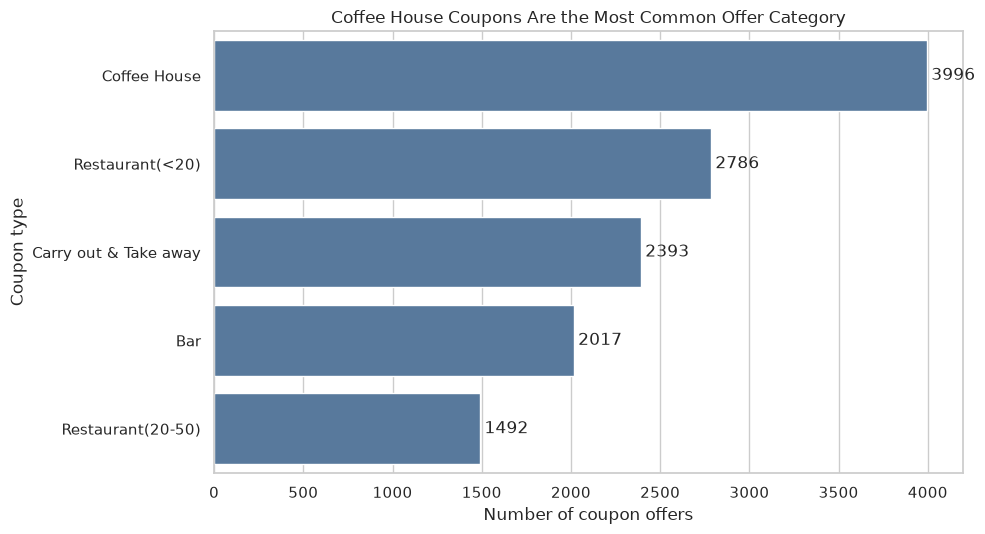

In [5]:
coupon_order = analysis_data["coupon"].value_counts().index
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.countplot(data=analysis_data, y="coupon", order=coupon_order, color="#4C78A8", ax=ax)
ax.set_title("Coffee House Coupons Are the Most Common Offer Category")
ax.set_xlabel("Number of coupon offers")
ax.set_ylabel("Coupon type")
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)
plt.tight_layout()
plt.show()


### Question 6: Histogram of the `temperature` column


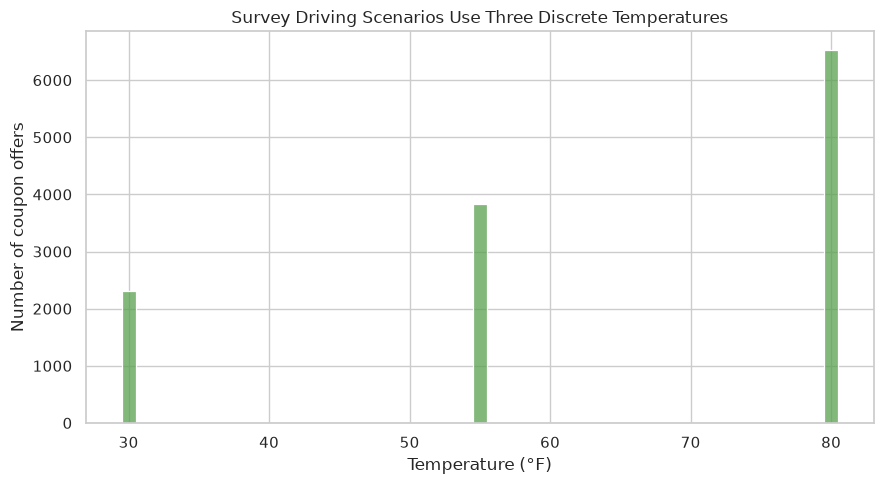

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=analysis_data, x="temperature", discrete=True, color="#59A14F", edgecolor="white", ax=ax)
ax.set_title("Survey Driving Scenarios Use Three Discrete Temperatures")
ax.set_xlabel("Temperature (°F)")
ax.set_ylabel("Number of coupon offers")
plt.tight_layout()
plt.show()


## 4. Investigating bar coupons

### Question 1: Create a DataFrame containing only bar coupons


In [ ]:
bar_coupons = analysis_data.loc[analysis_data["coupon"] == "Bar"].copy()
print(f"The bar-coupon DataFrame contains {len(bar_coupons):,} rows.")
bar_coupons.head()

The bar-coupon DataFrame contains 2,017 rows.


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,has_children,education,occupation,income,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
9,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,NaN,4~8,1~3,1,1,0,0,1,0
13,Home,Alone,Sunny,55,6PM,Bar,1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,NaN,4~8,1~3,1,0,0,1,0,1
17,Work,Alone,Sunny,55,7AM,Bar,1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,NaN,4~8,1~3,1,1,1,0,1,0
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,0,Bachelors degree,Architecture & Engineering,$62500 - $74999,never,less1,4~8,4~8,less1,1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,0,Bachelors degree,Architecture & Engineering,$62500 - $74999,never,less1,4~8,4~8,less1,1,0,0,1,0,1


### Question 2: What proportion of bar coupons were accepted?


In [8]:
bar_accepted = int(bar_coupons["Y"].sum())
bar_n = len(bar_coupons)
bar_rate = bar_coupons["Y"].mean()
bar_ci = proportion_confint(bar_accepted, bar_n, method="wilson")
print(f"{bar_accepted:,} of {bar_n:,} bar coupons were accepted: {bar_rate:.1%}.")
print(f"95% Wilson confidence interval: {bar_ci[0]:.1%} to {bar_ci[1]:.1%}.")
print(f"This is {(bar_rate-overall_rate)*100:.1f} percentage points below the overall coupon acceptance rate.")


827 of 2,017 bar coupons were accepted: 41.0%.
95% Wilson confidence interval: 38.9% to 43.2%.
This is -15.8 percentage points below the overall coupon acceptance rate.


In [9]:
def acceptance_summary(frame, group_col, order=None):
    result = frame.groupby(group_col, dropna=False)["Y"].agg(offers="size", accepted="sum", acceptance_rate="mean")
    result["acceptance_rate"] = result["acceptance_rate"].astype(float)
    if order is not None:
        result = result.reindex(order)
    return result

def chi_square_result(frame, group_mask, group_label="Target group", comparison_label="All other drivers"):
    groups = np.where(group_mask, group_label, comparison_label)
    table = pd.crosstab(groups, frame["Y"])
    chi2, p_value, _, _ = chi2_contingency(table)
    n = table.to_numpy().sum()
    cramers_v = np.sqrt(chi2 / n)
    return table, chi2, p_value, cramers_v

age_as_number = {"below21": 20, "21": 21, "26": 26, "31": 31, "36": 36, "41": 41, "46": 46, "50plus": 51}
bar_coupons["age_numeric"] = bar_coupons["age"].map(age_as_number)
bar_coupons["bar_more_than_once"] = bar_coupons["Bar"].isin(["1~3", "4~8", "gt8"])


### Question 3: Compare acceptance for drivers who went to a bar three or fewer times per month versus more than three times

The two groups exclude 21 bar-coupon records with an unreported bar-visit frequency. The result is a large descriptive gap in acceptance.


In [10]:
bar_visit_order = ["never", "less1", "1~3", "4~8", "gt8"]
display(acceptance_summary(bar_coupons, "Bar", bar_visit_order))

three_or_fewer = bar_coupons["Bar"].isin(["never", "less1", "1~3"])
more_than_three = bar_coupons["Bar"].isin(["4~8", "gt8"])
q3 = pd.DataFrame({
    "group": ["3 or fewer visits/month", "More than 3 visits/month"],
    "offers": [int(three_or_fewer.sum()), int(more_than_three.sum())],
    "acceptance_rate": [bar_coupons.loc[three_or_fewer, "Y"].mean(), bar_coupons.loc[more_than_three, "Y"].mean()]
})
display(q3.style.format({"acceptance_rate": "{:.1%}"}))
print(f"Acceptance was {q3.loc[1, 'acceptance_rate'] - q3.loc[0, 'acceptance_rate']:.1%} higher among drivers visiting bars more than three times per month.")


,offers,accepted,acceptance_rate
Bar,,,
never,830,156,0.188
less1,570,253,0.444
1~3,397,257,0.647
4~8,150,117,0.780
gt8,49,36,0.735


,group,offers,acceptance_rate
0,3 or fewer visits/month,1797,37.1%
1,More than 3 visits/month,199,76.9%


Acceptance was 39.8% higher among drivers visiting bars more than three times per month.


### Question 4: Compare drivers who go to a bar more than once per month and are over age 25 with all others

Ages are converted to representative numeric values solely to apply the assignment’s age threshold; `below21` is treated as 20 and `50plus` as 51. The targeted group is defined as `Bar` in {1–3, 4–8, >8} **and** age >25.


In [11]:
q4_target = bar_coupons["bar_more_than_once"] & (bar_coupons["age_numeric"] > 25)
q4_rates = pd.DataFrame({
    "group": ["More than once/month and over 25", "All other bar-coupon drivers"],
    "offers": [int(q4_target.sum()), int((~q4_target).sum())],
    "acceptance_rate": [bar_coupons.loc[q4_target, "Y"].mean(), bar_coupons.loc[~q4_target, "Y"].mean()]
})
display(q4_rates.style.format({"acceptance_rate": "{:.1%}"}))
_, chi2, p, v = chi_square_result(bar_coupons, q4_target)
print(f"Difference: {(q4_rates.loc[0, 'acceptance_rate'] - q4_rates.loc[1, 'acceptance_rate']):.1%} percentage points.")
print(f"Chi-square test: χ²={chi2:.1f}, p={p:.2e}, Cramér’s V={v:.3f}. The descriptive difference is substantial.")


,group,offers,acceptance_rate
0,More than once/month and over 25,420,69.5%
1,All other bar-coupon drivers,1597,33.5%


Difference: 36.0% percentage points.
Chi-square test: χ²=176.9, p=2.29e-40, Cramér’s V=0.296. The descriptive difference is substantial.


### Question 5: Compare drivers who go to bars more than once a month, have no child passenger, and do not work in farming/fishing/forestry with all others


In [12]:
q5_target = (
    bar_coupons["bar_more_than_once"]
    & (bar_coupons["passanger"] != "Kid(s)")
    & (bar_coupons["occupation"] != "Farming Fishing & Forestry")
)
q5_rates = pd.DataFrame({
    "group": ["Targeted profile", "All other bar-coupon drivers"],
    "offers": [int(q5_target.sum()), int((~q5_target).sum())],
    "acceptance_rate": [bar_coupons.loc[q5_target, "Y"].mean(), bar_coupons.loc[~q5_target, "Y"].mean()]
})
display(q5_rates.style.format({"acceptance_rate": "{:.1%}"}))
_, chi2, p, v = chi_square_result(bar_coupons, q5_target)
print(f"Difference: {(q5_rates.loc[0, 'acceptance_rate'] - q5_rates.loc[1, 'acceptance_rate']):.1%} percentage points.")
print(f"Chi-square test: χ²={chi2:.1f}, p={p:.2e}, Cramér’s V={v:.3f}.")


,group,offers,acceptance_rate
0,Targeted profile,551,71.3%
1,All other bar-coupon drivers,1466,29.6%


Difference: 41.7% percentage points.
Chi-square test: χ²=286.4, p=2.97e-64, Cramér’s V=0.377.


### Question 6: Compare the combined profile with all other drivers

The combined profile satisfies **at least one** of the following: (1) bar visits more than once per month, no child passenger, and not widowed; (2) bar visits more than once per month and age under 30; or (3) inexpensive-restaurant visits more than four times per month and annual income below $50,000.


In [ ]:
income_below_50k = ["Less than $12500", "$12500 - $24999", "$25000 - $37499", "$37500 - $49999"]
condition_1 = (bar_coupons["bar_more_than_once"] & (bar_coupons["passanger"] != "Kid(s)") & (bar_coupons["maritalStatus"] != "Widowed"))
condition_2 = bar_coupons["bar_more_than_once"] & (bar_coupons["age_numeric"] < 30)
condition_3 = bar_coupons["RestaurantLessThan20"].isin(["4~8", "gt8"]) & bar_coupons["income"].isin(income_below_50k)
q6_target = condition_1 | condition_2 | condition_3
q6_rates = pd.DataFrame({
    "group": ["Matches one or more profile conditions", "All other bar-coupon drivers"],
    "offers": [int(q6_target.sum()), int((~q6_target).sum())],
    "acceptance_rate": [bar_coupons.loc[q6_target, "Y"].mean(), bar_coupons.loc[~q6_target, "Y"].mean()]
})


group										offers	acceptance_rate

0	Matches one or more profile conditions	776		58.9%

1	All other bar-coupon drivers			1241	29.8%


### Question 7: Hypothesis about drivers who accept bar coupons

Drivers who accept bar coupons appear more likely to be frequent bar visitors. Acceptance is especially high among drivers who visit bars more than once per month, are over 25, and are not travelling with a child. These characteristics should be considered targeting signals rather than causes: the survey is not an experiment, and these factors may overlap with unobserved lifestyle and travel-context differences.

The chart below summarizes the main bar-coupon comparisons.


/tmp/ipykernel_775/1994878256.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bar_comparison, y="profile", x="acceptance_rate", palette=colors, ax=ax)


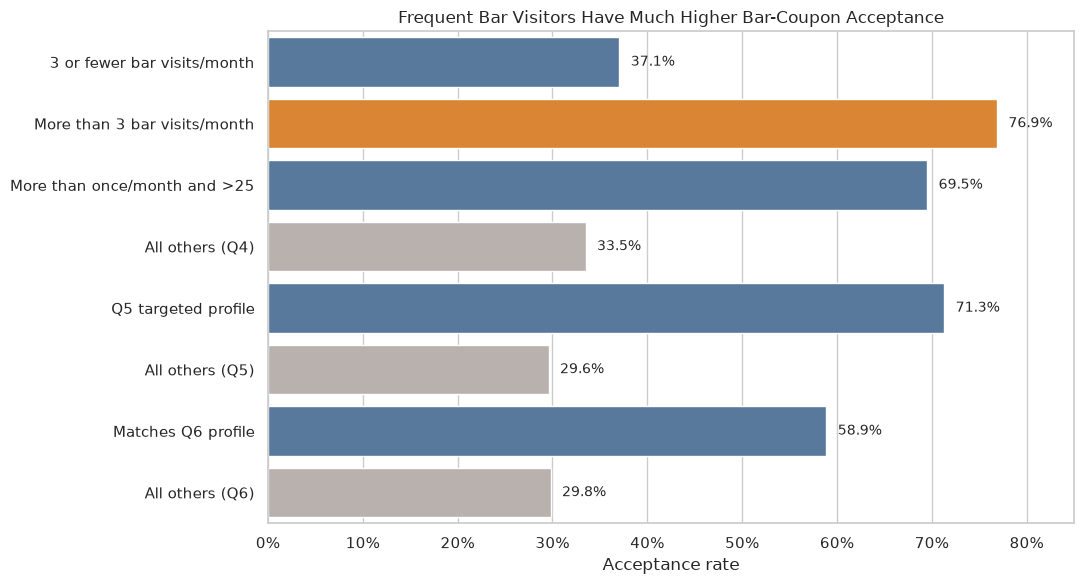

In [14]:
bar_comparison = pd.DataFrame({
    "profile": ["3 or fewer bar visits/month", "More than 3 bar visits/month", "More than once/month and >25", "All others (Q4)", "Q5 targeted profile", "All others (Q5)", "Matches Q6 profile", "All others (Q6)"],
    "acceptance_rate": [
        bar_coupons.loc[three_or_fewer, "Y"].mean(), bar_coupons.loc[more_than_three, "Y"].mean(),
        bar_coupons.loc[q4_target, "Y"].mean(), bar_coupons.loc[~q4_target, "Y"].mean(),
        bar_coupons.loc[q5_target, "Y"].mean(), bar_coupons.loc[~q5_target, "Y"].mean(),
        bar_coupons.loc[q6_target, "Y"].mean(), bar_coupons.loc[~q6_target, "Y"].mean(),
    ]
})
fig, ax = plt.subplots(figsize=(11, 6))
colors = ["#4C78A8", "#F58518", "#4C78A8", "#BAB0AC", "#4C78A8", "#BAB0AC", "#4C78A8", "#BAB0AC"]
sns.barplot(data=bar_comparison, y="profile", x="acceptance_rate", palette=colors, ax=ax)
ax.set_xlim(0, 0.85)
ax.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.set_xlabel("Acceptance rate")
ax.set_ylabel("")
ax.set_title("Frequent Bar Visitors Have Much Higher Bar-Coupon Acceptance")
for i, value in enumerate(bar_comparison["acceptance_rate"]):
    ax.text(value + 0.012, i, f"{value:.1%}", va="center", fontsize=10)
plt.tight_layout()
plt.show()


## 5. Independent investigation: Coffee House coupons

This investigation evaluates coffee-house coupons to determine characteristics associated with acceptance. The primary hypothesis is that drivers with a stronger prior coffee-house habit, more time to redeem a coupon, and a shorter trip to the venue will be more likely to accept.


In [15]:
coffee_coupons = analysis_data.loc[analysis_data["coupon"] == "Coffee House"].copy()
coffee_coupons["frequent_coffee_visitor"] = coffee_coupons["CoffeeHouse"].isin(["4~8", "gt8"])
print(f"Coffee-house coupon records: {len(coffee_coupons):,}")
print(f"Coffee-house acceptance rate: {coffee_coupons['Y'].mean():.1%}")
display(acceptance_summary(coffee_coupons, "CoffeeHouse", ["never", "less1", "1~3", "4~8", "gt8"]))


Coffee-house coupon records: 3,996
Coffee-house acceptance rate: 49.9%


,offers,accepted,acceptance_rate
CoffeeHouse,,,
never,927,175,0.189
less1,1075,518,0.482
1~3,1042,675,0.648
4~8,538,369,0.686
gt8,342,225,0.658


In [16]:
coffee_key_comparisons = pd.DataFrame({
    "comparison": [
        "Frequent coffee visitors (4+ visits/month)", "All other reported visit frequencies",
        "One-day expiration", "Two-hour expiration",
        "Trip under 15 minutes", "Trip of 15+ minutes"
    ],
    "offers": [
        int(coffee_coupons["frequent_coffee_visitor"].sum()), int((~coffee_coupons["frequent_coffee_visitor"]).sum()),
        int((coffee_coupons["expiration"] == "1d").sum()), int((coffee_coupons["expiration"] == "2h").sum()),
        int((coffee_coupons["toCoupon_GEQ15min"] == 0).sum()), int((coffee_coupons["toCoupon_GEQ15min"] == 1).sum())
    ],
    "acceptance_rate": [
        coffee_coupons.loc[coffee_coupons["frequent_coffee_visitor"], "Y"].mean(), coffee_coupons.loc[~coffee_coupons["frequent_coffee_visitor"], "Y"].mean(),
        coffee_coupons.loc[coffee_coupons["expiration"] == "1d", "Y"].mean(), coffee_coupons.loc[coffee_coupons["expiration"] == "2h", "Y"].mean(),
        coffee_coupons.loc[coffee_coupons["toCoupon_GEQ15min"] == 0, "Y"].mean(), coffee_coupons.loc[coffee_coupons["toCoupon_GEQ15min"] == 1, "Y"].mean()
    ]
})
display(coffee_key_comparisons.style.format({"acceptance_rate": "{:.1%}"}))

for label, mask in {
    "Frequent coffee visitor": coffee_coupons["frequent_coffee_visitor"],
    "One-day expiration": coffee_coupons["expiration"] == "1d",
    "Trip under 15 minutes": coffee_coupons["toCoupon_GEQ15min"] == 0,
}.items():
    _, chi2, p, v = chi_square_result(coffee_coupons, mask)
    print(f"{label}: χ²={chi2:.1f}, p={p:.2e}, Cramér’s V={v:.3f}")


,comparison,offers,acceptance_rate
0,Frequent coffee visitors (4+ visits/month),880,67.5%
1,All other reported visit frequencies,3116,45.0%
2,One-day expiration,1769,58.4%
3,Two-hour expiration,2227,43.2%
4,Trip under 15 minutes,1923,54.8%
5,Trip of 15+ minutes,2073,45.4%


Frequent coffee visitor: χ²=138.5, p=5.57e-32, Cramér’s V=0.186
One-day expiration: χ²=90.5, p=1.87e-21, Cramér’s V=0.150
Trip under 15 minutes: χ²=35.0, p=3.28e-09, Cramér’s V=0.094


/tmp/ipykernel_775/277050048.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coffee_plot, y="comparison", x="acceptance_rate", palette=colors, ax=ax)


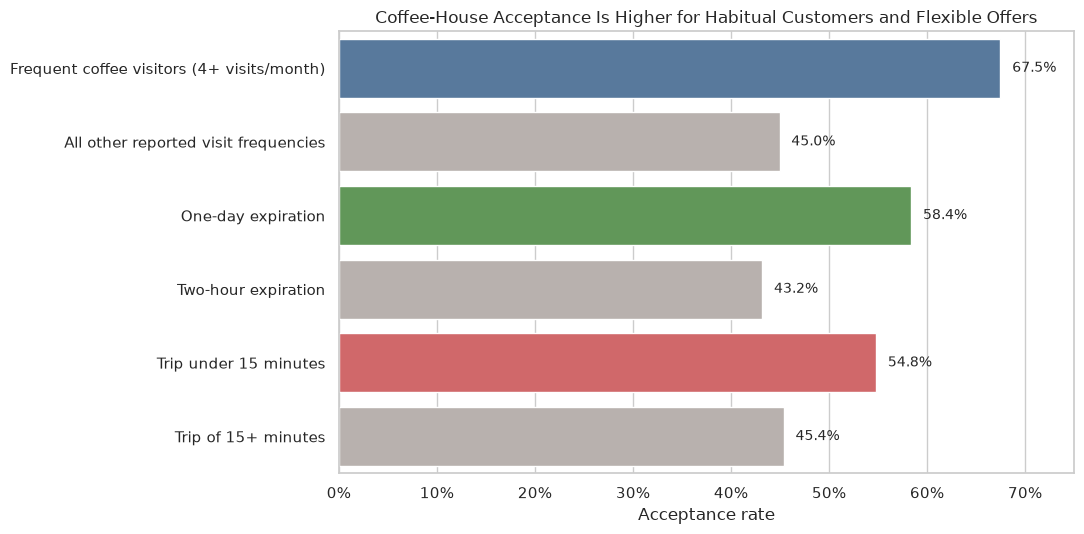

In [17]:
coffee_plot = coffee_key_comparisons.copy()
fig, ax = plt.subplots(figsize=(11, 5.5))
colors = ["#4C78A8", "#BAB0AC", "#59A14F", "#BAB0AC", "#E15759", "#BAB0AC"]
sns.barplot(data=coffee_plot, y="comparison", x="acceptance_rate", palette=colors, ax=ax)
ax.set_xlim(0, 0.75)
ax.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.set_xlabel("Acceptance rate")
ax.set_ylabel("")
ax.set_title("Coffee-House Acceptance Is Higher for Habitual Customers and Flexible Offers")
for i, value in enumerate(coffee_plot["acceptance_rate"]):
    ax.text(value + 0.012, i, f"{value:.1%}", va="center", fontsize=10)
plt.tight_layout()
plt.show()


## 6. Findings, actionable items, and recommendations

### Findings

| Finding | Evidence from this dataset | Practical interpretation |
|---|---:|---|
| Overall coupon response is positive but varies by offer type. | 56.8% overall acceptance; bar coupons 41.0%, carry-out/take-away 73.5%, and inexpensive restaurant coupons 70.7%. | Coupon category should be part of campaign prioritization. |
| Bar-coupon acceptance aligns closely with previous bar behavior. | Drivers visiting bars >3 times/month accepted 76.9% of bar offers versus 37.1% among those visiting ≤3 times/month. | Prior venue engagement is a strong descriptive targeting signal. |
| A multi-attribute bar profile has a sizable acceptance gap. | More-than-once/month visitors over 25 accepted 69.5% versus 33.5% for all other bar-coupon drivers. | Use behavioral and contextual segmentation rather than a uniform bar-coupon audience. |
| Coffee-house habits and redemption flexibility are associated with acceptance. | Frequent coffee visitors accepted 67.5% versus 44.9% for others; one-day expiry offers accepted 58.4% versus 43.2% for two-hour offers. | Prior purchase behavior and offer constraints can guide coffee-coupon targeting. |

### Actionable recommendations

1. **Prioritize coupon types with high baseline acceptance.** Inexpensive-restaurant and carry-out/take-away offers had acceptance above 70%, making them promising options when the objective is broad redemption.
2. **Target bar coupons selectively.** Favor customers with a history of visiting bars more than once per month, especially when they are not travelling with children. Avoid interpreting this as a demographic rule; it is a behavioral segmentation signal from this dataset.
3. **Give coffee-house offers longer validity windows when possible.** A one-day expiration was associated with a 15.2-percentage-point higher acceptance rate than a two-hour expiration in the observed records.
4. **Reduce redemption friction.** Coffee-house offers where the venue was less than 15 minutes away had a 54.8% acceptance rate compared with 45.4% when the trip was 15 minutes or longer.
5. **Validate these associations experimentally.** Before operational deployment, use randomized A/B tests to estimate causal lift, monitor fairness, and verify whether the patterns generalize to the intended customer population.

### Limitations

The data reflect survey scenarios rather than observed transactions, so stated acceptance may differ from actual redemption. Responses may not represent all drivers because the data were collected through a survey. Several visit-frequency fields contain missing values, which were retained rather than imputed. Lastly, the comparisons are bivariate/descriptive; correlated characteristics may explain part of the observed differences.
